# Assignment No. 4: Machine Learning Model Application & Evaluation

**Course:** Introduction to Data Science

## 1. Problem Definition

### Dataset Description
The Student Performance dataset contains information about students, including their gender, parental education, lunch type, test preparation course, and mathematics, reading, and writing scores.

### Problem Statement
The objective is to predict students' mathematics scores using their personal and educational information and their reading and writing scores.

### Features (X)
- Gender
- Race/ethnicity
- Parental level of education
- Lunch
- Test preparation course
- Reading score
- Writing score

### Target (y)
Math score

### Problem Type
This is a **Regression** problem because the target variable, math score, is a numerical value.

### Machine Learning Models
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving StudentsPerformance.csv to StudentsPerformance (1).csv
Dataset loaded successfully!
Dataset shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [2]:
# Select features (X) and target (y)

X = df.drop("math score", axis=1)
y = df["math score"]

print("Features (X):")
display(X.head())

print("Target (y):")
display(y.head())

print("Number of features:", X.shape[1])
print("Number of target values:", y.shape[0])

Features (X):


,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


Target (y):


,math score
0,72
1,69
2,90
3,47
4,76


Number of features: 7
Number of target values: 1000


In [5]:
# Select features and target

X = df.drop("math score", axis=1)
y = df["math score"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (1000, 7)
Target (y): (1000,)


In [6]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (800, 7)
Testing features: (200, 7)
Training target: (800,)
Testing target: (200,)


In [7]:
# Prepare categorical and numerical features

categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(include=["number"]).columns

# Process the features
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", SimpleImputer(strategy="median"), numerical_features)
    ]
)

# Create the three models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# Train each model
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll three models have been trained.")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All three models have been trained.


In [8]:
# Evaluate all three models

results = []

for name, model in trained_models.items():

    # Predict math scores on unseen test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 3)
    })

# Create comparison table
results_df = pd.DataFrame(results)

print("MODEL COMPARISON")
display(results_df)

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.21,5.39,0.880
1,Decision Tree,6.24,7.78,0.751
2,Random Forest,4.67,6.03,0.851


### Model Comparison and Interpretation

Three regression models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

Linear Regression performed best, achieving an MAE of 4.21, RMSE of 5.39, and R² Score of 0.880. Random Forest was the second-best model, with an MAE of 4.67, RMSE of 6.03, and R² Score of 0.851. Decision Tree performed worst, with an MAE of 6.24, RMSE of 7.78, and R² Score of 0.751.

Linear Regression was selected as the best model because it had the lowest prediction errors and the highest R² Score on the test data.

In [9]:
# Compare training and testing performance

for name, model in trained_models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    print(name)
    print("Training R2:", round(train_r2, 3))
    print("Testing R2:", round(test_r2, 3))
    print()

Linear Regression
Training R2: 0.874
Testing R2: 0.88

Decision Tree
Training R2: 1.0
Testing R2: 0.751

Random Forest
Training R2: 0.976
Testing R2: 0.851



## Final Conclusion

In this assignment, three regression models—Linear Regression, Decision Tree Regressor, and Random Forest Regressor—were applied to the Student Performance dataset to predict students' mathematics scores.

The models were evaluated using MAE, RMSE, and R² Score on unseen test data. Linear Regression performed best, achieving an MAE of 4.21, an RMSE of 5.39, and an R² Score of 0.880.

R² Score was particularly useful for comparing how much variation in mathematics scores each model explained, while MAE provided an understandable measure of average prediction error. Linear Regression was selected because it achieved the lowest MAE and RMSE and the highest test R² Score.

The training and testing results suggest that Linear Regression generalizes well, with no obvious sign of overfitting. The Decision Tree shows a strong sign of overfitting because its training R² is 1.000 while its testing R² is 0.751. Random Forest also shows some overfitting, with a training R² of 0.976 and testing R² of 0.851.

Overall, Linear Regression was the best-performing model for this dataset and prediction task.

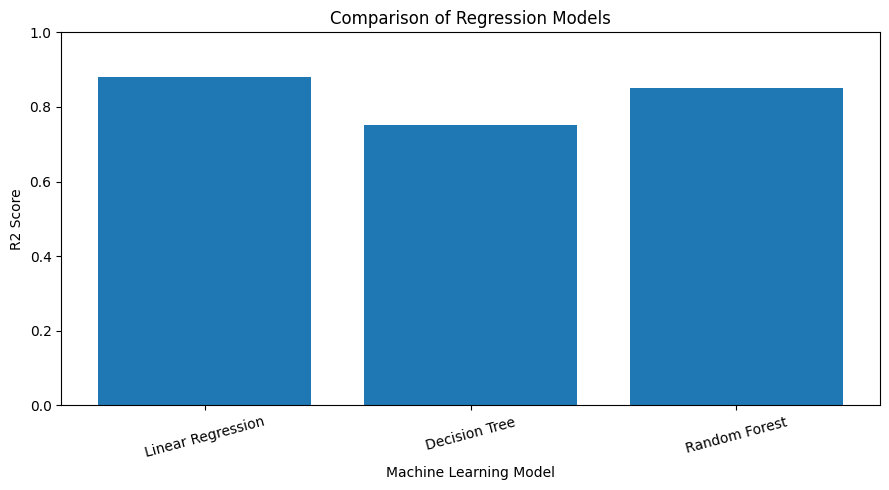

In [10]:
# Visualize Model Performance

plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["R2 Score"])

plt.title("Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R2 Score")
plt.ylim(0, 1)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()